# Product Recognition & Smart Inventory — CNN + YOLO + Gradio + Supabase

This Google Colab notebook downloads the six Kaggle datasets supplied by the user using `kagglehub`, inspects their structures, builds a unified image dataset, trains:
1. **CNN classifier:** EfficientNetB0 transfer learning (Keras)
2. **YOLO classifier:** Ultralytics YOLO classification

It evaluates accuracy on a held-out test split, saves both models, and launches a Gradio app for image upload/webcam capture. Predictions can be added to Supabase inventory with a single **Add +1** click, and the inventory can be filtered by category.

## Important expectations
- You supplied **six** dataset identifiers, not five: biscuit wrappers, plastic object detection, stationery, mobile phones, mouse/keyboard, bottles/cups.
- The sources may use different folder/annotation formats. The notebook inspects the downloaded files and makes a best-effort category mapping. It does not assume that every image in a dataset is appropriate or that the model will reach a particular accuracy.
- Some sources may be object-detection datasets with YOLO annotation files. This notebook trains YOLO **classification** from image classes because the datasets are heterogeneous. Object detection needs correctly formatted bounding-box labels; see the detection notes near the end.
- To record `phone +1`, the model needs product-level classes. The phone dataset is mapped to `phone`; broad classes are mapped to `biscuits`, `plastic_objects`, `stationery`, `phone`, `mouse_keyboard`, and `bottles_cups`. You can refine the mapping after inspecting the counts.
- Supabase service-role key is entered privately at runtime. Never publish it in GitHub or a shared notebook.

## 1. Install dependencies

In [ ]:
%pip -q install -U kagglehub ultralytics tensorflow gradio supabase scikit-learn pandas pillow matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 54.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.5/48.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 76.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 91.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 112.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 114.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 9

## 2. Imports and folders

In [ ]:
import os, json, shutil, random, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
ROOT = Path('/content/product_inventory_project')
RAW = ROOT / 'raw'
DATA = ROOT / 'dataset'
SPLIT = ROOT / 'split'
MODELS = ROOT / 'models'
for p in [RAW, DATA, SPLIT, MODELS]:
    p.mkdir(parents=True, exist_ok=True)
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
print("Project root:", ROOT)

Project root: /content/product_inventory_project


## 3. Download all supplied KaggleHub datasets

In [ ]:
import kagglehub

KAGGLE_DATASETS = {
    "biscuit_wrappers": "iamsouravbanerjee/biscuit-wrappers-dataset",
    "plastic_objects": "dataclusterlabs/plastic-object-detection-dataset",
    "stationery": "abdullahsami10/stationary-dataset",
    "phone": "dataclusterlabs/mobile-phone-image-dataset",
    "mouse_keyboard": "dataclusterlabs/electronics-mouse-keyboard-image-dataset",
    "bottles_cups": "dataclusterlabs/bottles-and-cups-dataset",
}

dataset_paths = {}
for category, dataset_id in KAGGLE_DATASETS.items():
    print(f"\nDownloading {category}: {dataset_id}")
    try:
        path = kagglehub.dataset_download(dataset_id)
        dataset_paths[category] = Path(path)
        print("Downloaded to:", path)
    except Exception as e:
        print(f"FAILED {dataset_id}: {type(e).__name__}: {e}")

print("\nDownload summary:")
for category in KAGGLE_DATASETS:
    print(category, "->", dataset_paths.get(category, "DOWNLOAD FAILED"))

100%|██████████| 1.30G/1.30G [00:25<00:00, 55.0MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/iamsouravbanerjee/biscuit-wrappers-dataset/versions/5



100%|██████████| 173M/173M [00:01<00:00, 144MB/s]

Extracting files...


...

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/dataclusterlabs/electronics-mouse-keyboard-image-dataset/versions/2



100%|██████████| 207M/207M [00:01<00:00, 184MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/dataclusterlabs/bottles-and-cups-dataset/versions/3

Download summary:
biscuit_wrappers -> /root/.cache/kagglehub/datasets/iamsouravbanerjee/biscuit-wrappers-dataset/versions/5
plastic_objects -> /root/.cache/kagglehub/datasets/dataclusterlabs/plastic-object-detection-dataset/versions/1
stationery -> /root/.cache/kagglehub/datasets/abdullahsami10/stationary-dataset/versions/1
phone -> /root/.cache/kagglehub/datasets/dataclusterlabs/mobile-phone-image-dataset/versions/2
mouse_keyboard -> /root/.cache/kagglehub/datasets/dataclusterlabs/electronics-mouse-keyboard-image-dataset/versions/2
bottles_cups -> /root/.cache/kagglehub/datasets/dataclusterlabs/bottles-and-cups-dataset/versions/3


## 4. Inspect each downloaded dataset

This prints example paths and image counts before any training. Use the output to confirm the download actually contains images.

In [ ]:
def list_images(folder):
    folder = Path(folder)
    return [p for p in folder.rglob('*')
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS]

for category, folder in dataset_paths.items():
    imgs = list_images(folder)
    print(f"\n{category}: {len(imgs)} images in {folder}")
    for p in imgs[:5]:
        print("  ", p.relative_to(folder))


biscuit_wrappers: 5058 images in /root/.cache/kagglehub/datasets/iamsouravbanerjee/biscuit-wrappers-dataset/versions/5
   Biscuit Wrappers Dataset/Britannia Good Day Harmony Biscuit/Britannia Good Day Harmony Biscuit (29).jpg
   Biscuit Wrappers Dataset/Britannia Good Day Harmony Biscuit/Britannia Good Day Harmony Biscuit (23).jpg
   Biscuit Wrappers Dataset/Britannia Good Day Harmony Biscuit/Britannia Good Day Harmony Biscuit (3).jpg
   Biscuit Wrappers Dataset/Britannia Good Day Harmony Biscuit/Britannia Good Day Harmony Biscuit (8).jpg
   Biscuit Wrappers Dataset/Britannia Good Day Harmony Biscuit/Britannia Good Day Harmony Biscuit (46).jpg

plastic_objects: 70 images in /root/.cache/kagglehub/datasets/dataclusterlabs/plastic-object-detection-dataset/versions/1
   plastic_images/plastic_images/dc_plastic_000052_GzL0izbV.jpg
   plastic_images/plastic_images/dc_plastic_000030_w6f4yUiS.jpg
   plastic_images/plastic_images/dc_plastic_000043_SrWFpmle.jpg
   plastic_images/plastic_images

## 5. Build unified category folders

All images are assigned to the broad class associated with the dataset source. This is a practical starting point, but check the source datasets: if a dataset contains unrelated objects, annotations, or non-product images, filter them before training. Duplicate images are not automatically deduplicated across datasets.

In [ ]:
if DATA.exists():
    shutil.rmtree(DATA)
DATA.mkdir(parents=True, exist_ok=True)

# Map each supplied dataset to a product-level or product-family class.
# These labels describe the dataset source, not necessarily individual SKU/brand.
source_to_class = {
    "biscuit_wrappers": "biscuits",
    "plastic_objects": "plastic_objects",
    "stationery": "stationery",
    "phone": "phone",
    "mouse_keyboard": "mouse_keyboard",
    "bottles_cups": "bottles_cups",
}

copy_counts = {}
for source_name, folder in dataset_paths.items():
    class_name = source_to_class[source_name]
    out = DATA / class_name
    out.mkdir(parents=True, exist_ok=True)
    count = 0
    for src in list_images(folder):
        # Verify image can be opened before copying.
        try:
            with Image.open(src) as im:
                im.verify()
            target = out / f"{source_name}_{count:08d}_{src.name}"
            shutil.copy2(src, target)
            count += 1
        except Exception:
            pass
    copy_counts[class_name] = count

display(pd.DataFrame([{"class": k, "images": v} for k, v in copy_counts.items()]))
print("Unified dataset:", DATA)

,class,images
0,biscuits,5058
1,plastic_objects,70
2,stationery,329
3,phone,100
4,mouse_keyboard,100
5,bottles_cups,100


Unified dataset: /content/product_inventory_project/dataset


## 6. Split data into train / validation / test

The split is done within each class. Very small classes may not support reliable evaluation. For robust accuracy, use enough images per class and check for near-duplicate images across splits.

In [ ]:
if SPLIT.exists():
    shutil.rmtree(SPLIT)
for split in ['train', 'val', 'test']:
    for class_dir in DATA.iterdir():
        if class_dir.is_dir():
            (SPLIT / split / class_dir.name).mkdir(parents=True, exist_ok=True)

split_summary = []
for class_dir in sorted([p for p in DATA.iterdir() if p.is_dir()]):
    imgs = list_images(class_dir)
    random.Random(SEED).shuffle(imgs)
    n = len(imgs)
    if n < 3:
        print(f"WARNING: {class_dir.name} has only {n} images; need at least 3 to split.")
        continue
    n_test = max(1, int(n * 0.15))
    n_val = max(1, int(n * 0.15))
    while n_test + n_val >= n:
        n_test = max(0, n_test - 1)
        n_val = max(0, n_val - 1)
    test_imgs = imgs[:n_test]
    val_imgs = imgs[n_test:n_test+n_val]
    train_imgs = imgs[n_test+n_val:]
    for split_name, group in [('train', train_imgs), ('val', val_imgs), ('test', test_imgs)]:
        for i, src in enumerate(group):
            shutil.copy2(src, SPLIT/split_name/class_dir.name/f'{i:08d}_{src.name}')
    split_summary.append({
        'class': class_dir.name, 'all': n,
        'train': len(train_imgs), 'val': len(val_imgs), 'test': len(test_imgs)
    })
display(pd.DataFrame(split_summary))
class_names = [r['class'] for r in split_summary if r['train'] > 0 and r['val'] > 0]
if len(class_names) < 2:
    raise ValueError("Not enough usable classes. Inspect download counts and ensure at least 3 valid images per class.")
print("Classes for training:", class_names)

,class,all,train,val,test
0,biscuits,5058,3542,758,758
1,bottles_cups,100,70,15,15
2,mouse_keyboard,100,70,15,15
3,phone,100,70,15,15
4,plastic_objects,70,50,10,10
5,stationery,329,231,49,49


Classes for training: ['biscuits', 'bottles_cups', 'mouse_keyboard', 'phone', 'plastic_objects', 'stationery']


## 7. Train CNN (EfficientNetB0 transfer learning)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT/'train', class_names=class_names, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, label_mode='int', shuffle=True, seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT/'val', class_names=class_names, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, label_mode='int', shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT/'test', class_names=class_names, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, label_mode='int', shuffle=False
)
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
])
base = EfficientNetB0(include_top=False, weights='imagenet',
                      input_shape=(*IMG_SIZE, 3))
base.trainable = False

inputs = layers.Input(shape=(*IMG_SIZE, 3))
x = augmentation(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)
cnn_model = models.Model(inputs, outputs, name='product_cnn_efficientnetb0')
cnn_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(str(MODELS/'cnn_best.keras'), monitor='val_accuracy', save_best_only=True)
]
history = cnn_model.fit(train_ds, validation_data=val_ds, epochs=3, callbacks=callbacks)

Found 4033 files belonging to 6 classes.
Found 862 files belonging to 6 classes.
Found 862 files belonging to 6 classes.
Epoch 1/3
127/127 ━━━━━━━━━━━━━━━━━━━━ 447s 3s/step - accuracy: 0.9301 - loss: 0.2315 - val_accuracy: 0.9849 - val_loss: 0.0865
Epoch 2/3
127/127 ━━━━━━━━━━━━━━━━━━━━ 440s 3s/step - accuracy: 0.9804 - loss: 0.0726 - val_accuracy: 0.9896 - val_loss: 0.0591
Epoch 3/3
127/127 ━━━━━━━━━━━━━━━━━━━━ 454s 3s/step - accuracy: 0.9854 - loss: 0.0492 - val_accuracy: 0.9884 - val_loss: 0.0500


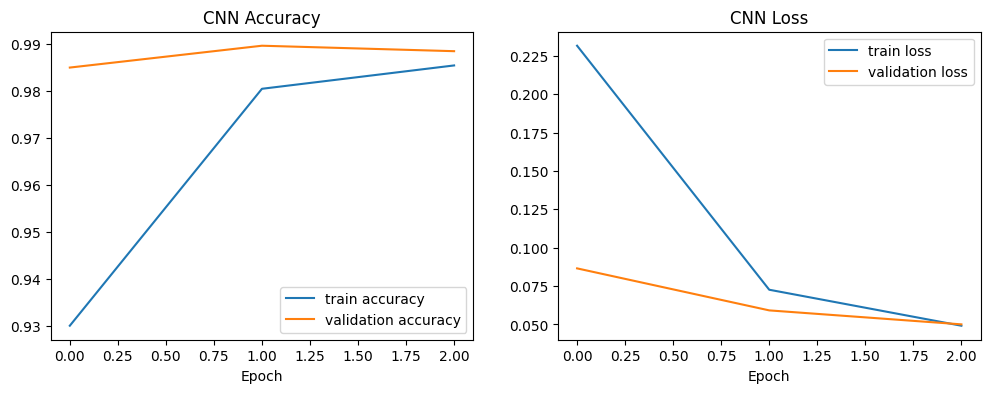

CNN test accuracy: 98.72% | test loss: 0.0458


102

In [ ]:
hist = pd.DataFrame(history.history)
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(hist['accuracy'], label='train accuracy')
plt.plot(hist['val_accuracy'], label='validation accuracy')
plt.title('CNN Accuracy'); plt.xlabel('Epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(hist['loss'], label='train loss')
plt.plot(hist['val_loss'], label='validation loss')
plt.title('CNN Loss'); plt.xlabel('Epoch'); plt.legend()
plt.show()

test_loss, test_acc = cnn_model.evaluate(test_ds, verbose=0)
print(f"CNN test accuracy: {test_acc*100:.2f}% | test loss: {test_loss:.4f}")
cnn_model.save(MODELS/'product_cnn.keras')
(MODELS/'class_names.json').write_text(json.dumps(class_names, indent=2))

## 8. Train YOLO classification model

In [ ]:
%pip install -U -q "ultralytics" "pillow<11.0.0"

from ultralytics import YOLO
import shutil
import tensorflow as tf

YOLO_DATA = ROOT/'yolo_classification'
if YOLO_DATA.exists():
    shutil.rmtree(YOLO_DATA)
for split_name in ['train','val','test']:
    for cls in class_names:
        (YOLO_DATA/split_name/cls).mkdir(parents=True, exist_ok=True)
        for src in list_images(SPLIT/split_name/cls):
            shutil.copy2(src, YOLO_DATA/split_name/cls/src.name)

yolo_model = YOLO('yolo11n-cls.pt')
yolo_model.train(
    data=str(YOLO_DATA),
    epochs=10,
    imgsz=224,
    batch=16,
    patience=3,
    project=str(MODELS/'yolo_runs'),
    name='product_yolo_cls',
    exist_ok=True,
    device=0 if tf.config.list_physical_devices('GPU') else 'cpu'
)
best_yolo_path = MODELS/'yolo_runs'/'product_yolo_cls'/'weights'/'best.pt'
if not best_yolo_path.exists():
    raise FileNotFoundError(f"YOLO weights not found: {best_yolo_path}")
yolo_best = YOLO(str(best_yolo_path))
if sum(len(list_images(YOLO_DATA/'test'/c)) for c in class_names) > 0:
    yolo_metrics = yolo_best.val(data=str(YOLO_DATA), split='test', imgsz=224)
    print("YOLO test metrics:", yolo_metrics.results_dict)
print("Saved YOLO weights:", best_yolo_path)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 28.5 MB/s eta 0:00:00
Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/product_inventory_project/yolo_classification, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, m

## 9. Bundle the models for download

In [ ]:
import zipfile
from pathlib import Path

# Ensure path variables exist even if runtime was restarted
try:
    ROOT
except NameError:
    ROOT = Path('/content/product_inventory_project')

try:
    MODELS
except NameError:
    MODELS = ROOT / 'models'

bundle = ROOT/'product_recognition_models.zip'
with zipfile.ZipFile(bundle, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in MODELS.rglob('*'):
        if p.is_file():
            z.write(p, p.relative_to(ROOT))
    if (MODELS/'class_names.json').exists():
        z.write(MODELS/'class_names.json', 'class_names.json')

print("Saved:", bundle)
from google.colab import files
try:
    files.download(str(bundle))
except Exception as e:
    print("Could not trigger automatic download. Error:", e)
    print("You can manually download the file from the file explorer pane on the left.")

Saved: /content/product_inventory_project/product_recognition_models.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Supabase SQL setup

In Supabase → SQL Editor, run:

```sql
create table if not exists public.inventory (
  product_name text primary key,
  category text not null,
  quantity integer not null default 0 check (quantity >= 0),
  updated_at timestamptz not null default now()
);

create table if not exists public.recognition_logs (
  id bigint generated always as identity primary key,
  product_name text not null,
  category text not null,
  confidence double precision,
  model_name text,
  source text not null default 'gradio',
  created_at timestamptz not null default now()
);

create or replace function public.add_inventory_item(
  p_product_name text,
  p_category text,
  p_confidence double precision default null,
  p_model_name text default 'cnn',
  p_source text default 'gradio'
) returns public.inventory
language plpgsql
security definer
set search_path = public
as $$
declare result_row public.inventory;
begin
  insert into public.inventory(product_name, category, quantity, updated_at)
  values (p_product_name, p_category, 1, now())
  on conflict (product_name)
  do update set quantity = public.inventory.quantity + 1,
                category = excluded.category,
                updated_at = now()
  returning * into result_row;

  insert into public.recognition_logs(product_name, category, confidence, model_name, source)
  values (p_product_name, p_category, p_confidence, p_model_name, p_source);
  return result_row;
end;
$$;

revoke all on function public.add_inventory_item(text,text,double precision,text,text) from public;
grant execute on function public.add_inventory_item(text,text,double precision,text,text) to service_role;
```

Use your Supabase **Project URL** and **service-role key** only in the private Colab runtime. Never paste them into a public notebook or GitHub repository.

In [ ]:
from supabase import create_client
import getpass

SUPABASE_URL = input("Supabase Project URL: ").strip()
SUPABASE_SERVICE_ROLE_KEY = getpass.getpass("Supabase service-role key (hidden): ").strip()

# Automatically strip trailing '/rest/v1/' or '/rest/v1' if the user accidentally copied it from API settings
if SUPABASE_URL.endswith("/rest/v1/"):
    SUPABASE_URL = SUPABASE_URL[:-9]
elif SUPABASE_URL.endswith("/rest/v1"):
    SUPABASE_URL = SUPABASE_URL[:-8]

if not SUPABASE_URL.startswith("https://") or not SUPABASE_SERVICE_ROLE_KEY:
    raise ValueError("Enter a valid Supabase URL and service-role key.")

supabase = create_client(SUPABASE_URL, SUPABASE_SERVICE_ROLE_KEY)
test = supabase.table('inventory').select('*').limit(5).execute()
print("Supabase connected. Inventory rows:", len(test.data or []))

Supabase Project URL: https://nnqrrvvmukgpjywjboaq.supabase.co/rest/v1/
Supabase service-role key (hidden): ··········
Supabase connected. Inventory rows: 5


## 11. Gradio upload/webcam recognition + category filter + inventory updates

In [ ]:
import gradio as gr
import pandas as pd
import numpy as np
import json
from pathlib import Path
import tensorflow as tf
from ultralytics import YOLO

# Dynamic recovery of project paths and dependencies if notebook restarted
try:
    ROOT
except NameError:
    ROOT = Path('/content/product_inventory_project')
try:
    MODELS
except NameError:
    MODELS = ROOT / 'models'
try:
    IMG_SIZE
except NameError:
    IMG_SIZE = (224, 224)

# Recover class_names
try:
    class_names
except NameError:
    class_json = MODELS/'class_names.json'
    if class_json.exists():
        class_names = json.loads(class_json.read_text())
    else:
        class_names = ['biscuits', 'bottles_cups', 'mouse_keyboard', 'phone', 'plastic_objects', 'stationery']

# Recover cnn_model
try:
    cnn_model
except NameError:
    cnn_path = MODELS/'product_cnn.keras'
    if cnn_path.exists():
        cnn_model = tf.keras.models.load_model(str(cnn_path))
    else:
        cnn_model = None

# Recover yolo_model
try:
    yolo_best
except NameError:
    yolo_path = MODELS/'yolo_runs'/'product_yolo_cls'/'weights'/'best.pt'
    if yolo_path.exists():
        yolo_best = YOLO(str(yolo_path))
    else:
        yolo_best = None

def predict_cnn(image):
    if image is None:
        return None, "Upload or capture an image first.", pd.DataFrame(columns=['Class','Confidence'])
    if cnn_model is None:
        return None, "CNN model weights not found! Please train or load your model first.", pd.DataFrame(columns=['Class','Confidence'])
    arr = np.asarray(image.convert('RGB').resize(IMG_SIZE), dtype=np.float32)
    probs = cnn_model.predict(np.expand_dims(arr, 0), verbose=0)[0]
    order = np.argsort(probs)[::-1]
    cls = class_names[int(order[0])]
    conf = float(probs[order[0]])
    scores = pd.DataFrame([{'Class': class_names[int(i)], 'Confidence': float(probs[i])} for i in order])
    state = {'product_name': cls, 'category': cls, 'confidence': conf, 'model_name': 'cnn'}
    return state, f"### Prediction: {cls}\nConfidence: {conf:.1%}", scores

def add_inventory(prediction, source):
    if not prediction:
        return "Recognize an image first."
    try:
        result = supabase.rpc('add_inventory_item', {
            'p_product_name': prediction['product_name'],
            'p_category': prediction['category'],
            'p_confidence': prediction['confidence'],
            'p_model_name': prediction['model_name'],
            'p_source': source
        }).execute()
        return f"Added +1 {prediction['product_name']} to Supabase. Database response: {result.data}"
    except Exception as e:
        return f"Supabase update failed: {type(e).__name__}: {e}"

def get_inventory(category):
    q = supabase.table('inventory').select('product_name,category,quantity,updated_at').order('updated_at', desc=True)
    if category and category != 'All':
        q = q.eq('category', category)
    res = q.execute()
    return pd.DataFrame(res.data or [], columns=['product_name','category','quantity','updated_at'])

def yolo_predict(image):
    if image is None:
        return "Upload or capture an image first."
    if yolo_best is None:
        return "YOLO model weights not found! Please train or load your model first."
    result = yolo_best.predict(source=image, verbose=False)[0]
    idx = int(result.probs.top1)
    return f"YOLO prediction: {result.names[idx]} — {float(result.probs.top1conf):.1%}"

with gr.Blocks(title='Product Recognition and Smart Inventory') as demo:
    gr.Markdown("# Product Recognition & Smart Inventory\nCNN prediction + YOLO comparison + Supabase inventory")
    state = gr.State(None)
    with gr.Row():
        image_input = gr.Image(type='pil', sources=['upload','webcam'], label='Upload or capture product')
        with gr.Column():
            pred_text = gr.Markdown("Prediction appears here.")
            score_table = gr.Dataframe(label='CNN class confidence scores', interactive=False)
            recognize = gr.Button('Recognize with CNN', variant='primary')
            add_btn = gr.Button('Add +1 to Supabase inventory')
            status = gr.Markdown()
            yolo_btn = gr.Button('Compare with YOLO')
            yolo_text = gr.Markdown()
    recognize.click(predict_cnn, inputs=image_input, outputs=[state,pred_text,score_table])
    add_btn.click(lambda p: add_inventory(p, 'gradio_upload_or_webcam'), inputs=state, outputs=status)
    yolo_btn.click(yolo_predict, inputs=image_input, outputs=yolo_text)

    gr.Markdown("## Supabase inventory")
    category_filter = gr.Dropdown(choices=['All'] + class_names, value='All', label='Filter by predicted category')
    inv = gr.Dataframe(label='Inventory table', interactive=False)
    refresh = gr.Button('Refresh inventory')
    refresh.click(get_inventory, inputs=category_filter, outputs=inv)
    category_filter.change(get_inventory, inputs=category_filter, outputs=inv)

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3a1bcb4006a7769403.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Important notes / limitations
- The six supplied datasets are mapped to broad labels (`biscuits`, `plastic_objects`, `stationery`, `phone`, `mouse_keyboard`, `bottles_cups`). The model can only learn what those datasets and labels represent.
- The plastic object detection dataset may contain object-detection annotations, but this notebook currently uses its images as a **classification class**. To train a YOLO detector that draws boxes around objects, labels must be converted to Ultralytics YOLO detection format and trained with a `data.yaml`.
- The notebook records the predicted class as `product_name`. To get exact brands/SKUs, train on brand/product-level labels.
- Check image counts and labels before trusting accuracy. A random split of related or duplicate images can inflate scores.
- If any KaggleHub dataset download fails due to permissions, network, or dataset changes, fix that download error before continuing.